# 실루엣 점수로 선택한 서울 따릉이 군집과 다음 한 시간의 수요 예측

2024년 12월의 2,766개 대여소를 완전연결법으로 묶는다. 다섯 거리 후보 중 평균 실루엣 점수가 가장 높은 거리를 선택한 뒤, 2023~2024년 출발·반납 기록을 새 군집에 배정한다. 예측 오차를 사용해 거리 기준을 고르지 않는다. 12월 명단과 위치를 과거에 고정한 회고 분석이며, 2024년 4분기는 앞선 실험에서도 평가한 기간이다.

In [1]:
from pathlib import Path
import os
import subprocess
import sys
from tempfile import TemporaryDirectory
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "전처리/rental_aggregate.py").is_file())
OUT = ROOT / "모델"
stations = pd.read_csv(ROOT / "따릉이 대여소 비교/서울 전체 직선거리 500m 군집 배정.csv")
stations = stations.loc[stations["기준월"].eq("2024-12")].set_index("대여소번호").sort_index()
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import pdist, squareform
from sklearn.metrics import silhouette_score

SITE = ROOT / "따릉이 대여소 비교"
hours = pd.date_range("2023-01-01","2025-01-01",freq="h",inclusive="left")
assert len(stations) == 2766 and stations.index.is_unique
plt.rcParams.update({"font.family": "Malgun Gothic" if os.name=="nt" else "sans-serif",
                     "axes.unicode_minus":False, "figure.dpi":110})

## 거리 후보 선택

거리 행렬은 위도·경도를 지구 반지름 6,371,008.8m의 대권거리로 변환해 산출한다. 완전연결 트리는 한 번 만들고 같은 트리를 300·400·500·600·700m에서 자른다. 대여소별 실루엣 점수를 동일한 가중치로 평균하며, 단독 군집의 점수는 0이다. 점수가 같으면 더 작은 거리를 택한다.

In [2]:
lat,lon = np.radians(stations[["위도","경도"]].to_numpy()).T
xyz = np.column_stack([np.cos(lat)*np.cos(lon), np.cos(lat)*np.sin(lon), np.sin(lat)])
arc = 2*6371008.8*np.arcsin(np.minimum(1,pdist(xyz)/2))
tree = linkage(arc,method="complete")
distance = squareform(arc)
partitions, rows = {}, []
for limit in [300,400,500,600,700]:
    raw = pd.Series(fcluster(tree,limit,criterion="distance"),index=stations.index)
    labels = raw.groupby(raw).transform(lambda members: members.index.min()).rename("군집번호")
    partitions[limit] = labels
    sizes = labels.value_counts()
    rows.append([limit,len(sizes),int(sizes.eq(1).sum()),silhouette_score(distance,labels,metric="precomputed")])
candidates = pd.DataFrame(rows,columns=["최대거리(m)","군집 수","단독 군집 수","평균 실루엣"])
limit = int(candidates.sort_values(["평균 실루엣","최대거리(m)"],ascending=[False,True]).iloc[0,0])
group = partitions[limit]
ids = pd.Index(sorted(group.unique()),name="군집번호")
np.testing.assert_array_equal(partitions[500],stations["완전연결 군집번호"])
for _,pos in group.groupby(group).indices.items():
    assert distance[np.ix_(pos,pos)].max() <= limit
assignment = stations[["대여소명","자치구","위도","경도"]].assign(군집번호=group)
assignment["군집 크기"] = group.map(group.value_counts())
assignment.to_csv(SITE/"실루엣 선택 군집 배정.csv",encoding="utf-8-sig")
candidates.to_csv(SITE/"군집 거리별 실루엣.csv",index=False,encoding="utf-8-sig")
display(candidates.round(5))
print(f"최고 점수 후보 {limit}m, {len(ids)}개 군집")
del distance,arc

,최대거리(m),군집 수,단독 군집 수,평균 실루엣
0,300,1517,654,0.37293
1,400,1229,332,0.40366
2,500,1021,166,0.41537
3,600,855,81,0.41767
4,700,743,47,0.41210


최고 점수 후보 600m, 855개 군집


## 월별 출발 건수를 군집에 배정

0분 또는 0m 대여를 제외하고 중복을 정리한 기존 전처리 집계를 사용한다. 원본 ZIP에서 다시 만들 때는 임시 폴더를 사용한다. 이미 만들어 둔 월별 집계 폴더가 있다면 환경변수 BIKE_AGGREGATE_CACHE로 지정할 수 있다. 매월 기존 서울 전체 합계와 50개 표본의 합계를 독립적으로 대조한다.

In [3]:
verified = pd.read_csv(ROOT / "전처리/월별 집계 검증.csv").set_index("월")
sample_ids = pd.read_csv(ROOT / "전처리/선정 대여소.csv").station_id
totals = np.zeros((len(hours), len(ids)), dtype=np.int32)
# 기준선에서 시차 대여량 중 예측 정시에 아직 반납이 확인되지 않은 건수를 뺀다.
late_returns = {lag: np.zeros_like(totals) for lag in (24, 168)}
# 각 출발 시간에 대해 1~24시간 후까지 확인된 누적 대여 건수를 저장한다.
confirmed = np.empty((len(hours), len(ids), 24), dtype=np.int16)
coverage = []
with TemporaryDirectory(prefix="cluster_demand_") as tmp:
    cached = os.environ.get("BIKE_AGGREGATE_CACHE")
    cache = Path(cached) if cached else Path(tmp)
    if not cached:
        subprocess.run([sys.executable, str(ROOT / "전처리/rental_aggregate.py"), str(cache)], check=True)
    for month, ref in verified.iterrows():
        start = hours.get_loc(pd.Timestamp(month))
        with np.load(cache / f"{month}.npz") as z:
            station_ids, counts = z["ids"], z["counts"]
        nh = counts.shape[1]
        assert nh == pd.Timestamp(month).days_in_month * 24
        assert counts.sum() == ref["집계 대여 건수"]
        assert counts[np.isin(station_ids, sample_ids)].sum() == ref["표본 50곳 대여 건수"]
        groups = group.reindex(station_ids)
        matched = groups.notna().to_numpy()
        cluster_idx = ids.get_indexer(groups[matched])
        np.add.at(totals[start:start+nh].T, cluster_idx, counts[matched])
        assigned = int(totals[start:start+nh].sum())
        assert assigned == counts[matched].sum()
        coverage.append((month, int(counts.sum()), assigned, int(counts[~matched].sum())))
        events = np.memmap(cache / f"{month}.bin", dtype="<i4", mode="r").reshape(-1, 3)
        assert len(events) == ref["필터 후 원천 행"] and np.count_nonzero(events[:,0]) == counts.sum()
        for lag, correction in late_returns.items():
            mask = (events[:,0] > 0) & (events[:,2] > events[:,1] + lag)
            delayed = events[mask, :2]
            positions = ids.get_indexer(group.reindex(delayed[:,0]))
            keep = (positions >= 0) & (delayed[:,1] + lag < len(hours))
            np.add.at(correction, (delayed[keep,1] + lag, positions[keep]), 1)
        # 반납 확인이 출발 다음 정시보다 늦은 대여만 지연 시간별로 센다.
        bins = np.zeros((26, nh, len(ids)), dtype=np.int32)
        for block_start in range(0, len(events), 250_000):
            block = events[block_start:block_start+250_000]
            delay = block[:,2] - block[:,1]
            delayed = (block[:,0] > 0) & (delay > 1)
            group_pos = ids.get_indexer(group.reindex(block[delayed,0]))
            keep = group_pos >= 0
            np.add.at(bins, (np.minimum(delay[delayed][keep],25),
                             block[delayed,1][keep] - start, group_pos[keep]), 1)
        pending = np.zeros((nh, len(ids)), dtype=np.int32)
        monthly_counts = totals[start:start+nh]
        assert monthly_counts.max() <= np.iinfo(np.int16).max
        for lag in range(24,0,-1):
            pending += bins[lag+1]
            as_known = monthly_counts - pending
            assert as_known.min() >= 0
            confirmed[start:start+nh,:,lag-1] = as_known
        del bins, block, events
demand = pd.DataFrame(totals, index=hours, columns=ids)
coverage = pd.DataFrame(coverage, columns=["월", "서울 전체", "군집 배정", "명단 외"])
assert len(coverage) == 24 and (coverage["서울 전체"] == coverage["군집 배정"] + coverage["명단 외"]).all()
annual = coverage.groupby(coverage["월"].str[:4])[["서울 전체", "군집 배정", "명단 외"]].sum()
annual["배정률(%)"] = 100 * annual["군집 배정"] / annual["서울 전체"]
display(annual.round(2))

,서울 전체,군집 배정,명단 외,배정률(%)
월,,,,
2023,43994125,42810716,1183409,97.31
2024,42688696,42219615,469081,98.90


## 2024년 수요가 많은 군집

군집 총량과 구성 대여소당 하루 평균을 따로 비교한다. 총량은 2024년의 합계이며, 대여소당 하루 평균은 총량을 366일과 12월 명단의 대여소 수로 나눈 값이다. 군집번호는 구성 대여소 번호 중 가장 작은 값이다.

In [4]:
members = stations.groupby(group)
summary = pd.DataFrame(index=ids)
summary["대여소 수"] = members.size()
summary["구성 대여소"] = members["대여소명"].agg(" · ".join)
summary["자치구"] = members["자치구"].agg(lambda values: " · ".join(sorted(set(values))))
for year in [2023, 2024]:
    summary[f"{year}년 출발 건수"] = demand.loc[str(year)].sum()
yearly = demand.loc["2024"]
days = yearly.index.normalize().nunique()
summary["2024년 대여소당 하루 평균"] = summary["2024년 출발 건수"] / (days * summary["대여소 수"])
assert days == 366 and summary["2024년 출발 건수"].sum() == annual.loc["2024","군집 배정"]
for metric in ["2024년 출발 건수", "2024년 대여소당 하루 평균"]:
    display(summary.nlargest(5, metric)[["자치구","구성 대여소","대여소 수",metric]].round(2))

,자치구,구성 대여소,대여소 수,2024년 출발 건수
군집번호,,,,
1198,강서구,LG 사이언스파크 · 마곡나루역 5번출구 뒤편 · 마곡나루역 2번 출구 · 마곡나루...,5,431024
1124,강서구,"발산역 6번 출구 뒤 · 발산역 1번, 9번 인근 대여소 · 마곡메가박스 앞 · 명...",8,344806
1151,강서구,마곡역1번출구 · 마곡역교차로 · 마곡역 교차로(2번출구) · 마곡역 버스정류장(마...,8,327560
1210,송파구,롯데월드타워(잠실역2번출구 쪽) · 잠실역 6번출구 · 잠실역 8번출구 · 잠실 자...,5,265649
230,영등포구,영등포구청역 1번출구 · 남부고용노동지청 남측 · 양평1동 YP센터 앞 · 이앤씨드...,7,255545


,자치구,구성 대여소,대여소 수,2024년 대여소당 하루 평균
군집번호,,,,
4217,마포구,한강공원 망원나들목,1,367.94
1198,강서구,LG 사이언스파크 · 마곡나루역 5번출구 뒤편 · 마곡나루역 2번 출구 · 마곡나루...,5,235.53
502,광진구,뚝섬유원지역 1번출구 앞 · 뚝섬 유원지역,2,215.24
2620,송파구,송파나루역 4번 출구옆 · 방이삼거리,2,180.30
207,영등포구,여의나루역 1번출구 앞 · LG트윈타워 앞,2,176.78


## 평일과 휴일의 시간대별 패턴

기상·달력 파일의 공휴일 표시를 사용해 주말·공휴일과 나머지 평일을 구분한다. 시간대별 평균의 분모는 해당 유형의 날짜 수다. 피크 시각은 0~23시 중 평균 출발 건수가 최대인 시간의 시작이며, 동률이면 빠른 시각이다.

평일 전체 군집 평균 피크 18시, 군집당 16.03건
주말·공휴일 전체 군집 평균 피크 17시, 군집당 8.62건


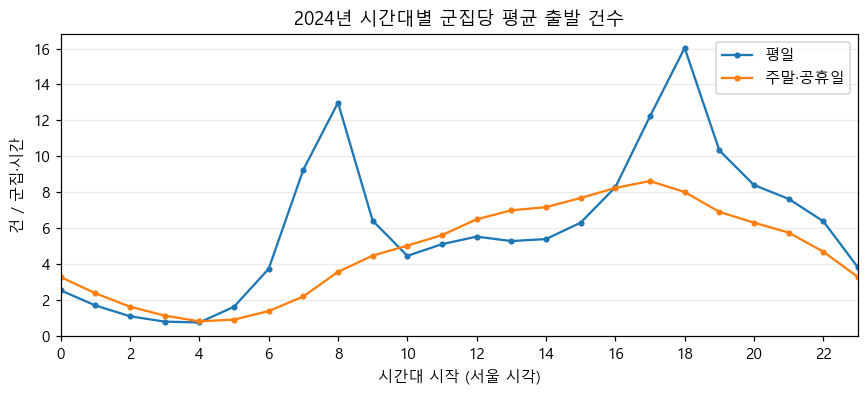

In [5]:
cal = pd.read_csv(ROOT / "분석용 데이터/Seoul_public_bicycle.csv", usecols=["datetime","holiday"],
                  parse_dates=["datetime"]).set_index("datetime")
holiday = cal.holiday.reindex(yearly.index)
assert holiday.isin([0,1]).all()
off = (yearly.index.weekday >= 5) | holiday.eq(1).to_numpy()
fig, ax = plt.subplots(figsize=(8,3.7))
for label, mask in [("평일", ~off), ("주말·공휴일", off)]:
    part = yearly.loc[mask]
    profile = part.groupby(part.index.hour).mean()
    summary[label + " 피크 시작시"] = profile.idxmax().where(profile.max() > 0).astype("Int64")
    avg = profile.mean(axis=1)
    ax.plot(avg.index, avg, label=label, marker="o", markersize=3)
    print(f"{label} 전체 군집 평균 피크 {avg.idxmax()}시, 군집당 {avg.max():.2f}건")
ax.set(title="2024년 시간대별 군집당 평균 출발 건수", xlabel="시간대 시작 (서울 시각)", ylabel="건 / 군집·시간",
       xticks=range(0,24,2), xlim=(0,23))
ax.grid(axis="y",alpha=.25)
ax.legend()
fig.tight_layout()
plt.show()
summary.to_csv(OUT / "실루엣 군집별 대여 수요.csv", encoding="utf-8-sig", float_format="%.4f")

## 다음 1시간 대여량 예측의 기준선

각 군집에서 전날 같은 시간 또는 전주 같은 시간의 대여량을 그대로 예측값으로 사용한다. 당시까지 반납이 확인된 건수만 입력에 포함한다. 2024년 각 분기의 동일한 군집·시간 전체에서 비교한다. 오차 단위는 한 군집의 한 시간당 대여 건수다. 12월 군집을 사용했으므로 이 결과는 회고 비교로 해석한다.

In [6]:
scores = []
for lag in (24, 168):
    observed = totals[:-lag] - late_returns[lag][lag:]
    assert observed.min() >= 0
    dates = hours[lag:]
    for quarter in range(1,5):
        selected = (dates.year == 2024) & (dates.quarter == quarter)
        error = (totals[lag:][selected] - observed[selected]).astype("float64")
        scores.append([quarter, "전날 동일 시간" if lag == 24 else "전주 동일 시간",
                       error.size, np.abs(error).mean(), np.sqrt(np.square(error).mean())])
scores = pd.DataFrame(scores, columns=["분기","기준선","군집·시간 수","MAE","RMSE"])
assert scores.groupby("기준선")["군집·시간 수"].sum().eq(len(yearly)*len(ids)).all()
display(scores.pivot(index="분기",columns="기준선",values=["MAE","RMSE"]).round(3))

MAE              RMSE         
기준선 전날 동일 시간 전주 동일 시간 전날 동일 시간 전주 동일 시간
분기                                     
1      2.431    2.336    4.876    4.490
2      4.008    3.799    7.868    7.319
3      3.497    3.459    6.926    6.816
4      3.009    2.853    6.310    5.641

## MLP·GRU를 네 입력 조건에서 새로 학습

한 모델이 모든 군집에서 학습하며 각 군집의 다음 한 시간 출발량을 예측한다. 기본 입력은 군집 임베딩, 반납이 확인된 직전 24시간·전주 동일 시간의 출발량, 달력과 직전 날씨다. 반납량만, 유사 기상만, 둘 다 추가한 버전도 각각 처음부터 학습한다. MLP는 시퀀스를 펼쳐서 읽고 GRU는 시간순으로 읽는다. 모든 조건에서 기존 실험과 동일한 MSE, Adam 0.001, 배치 8,192, 4에포크, 시드 42를 사용한다. 분기 경계 전에 확인될 수 있었던 학습 정답만 쓴다.

In [7]:
import torch
from torch import nn
import math

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH, EPOCHS, SEED = 8192, 4, 42
torch.set_num_threads(4)
torch.set_float32_matmul_precision("high")
N = len(ids)
deltas = torch.arange(24,0,-1,device=DEVICE)
np.testing.assert_array_equal(confirmed[:-24,:,23], totals[:-24] - late_returns[24][24:])
weekly = np.zeros_like(totals)
weekly[168:] = totals[:-168] - late_returns[168][168:]
assert weekly.min() >= 0 and weekly.max() <= np.iinfo(np.int16).max
past = torch.as_tensor(confirmed, device=DEVICE)
week = torch.as_tensor(weekly.astype(np.int16), device=DEVICE)
actual = torch.as_tensor(totals, device=DEVICE)
weather_names = ["temperature","humidity","precipitation","windspeed"]
wx = pd.read_csv(ROOT / "분석용 데이터/Seoul_public_bicycle.csv",parse_dates=["datetime"]).set_index("datetime")
w = wx[weather_names].reindex(hours - pd.Timedelta(hours=1)).to_numpy(dtype="float32")
fixed = np.column_stack([np.eye(24)[hours.hour], np.eye(7)[hours.weekday],
                         np.eye(12)[hours.month-1], wx.holiday.loc[hours].to_numpy()]).astype("float32")
def context_at(cutoff):
    reference = w[168:cutoff-23]
    median = np.nanmedian(reference,axis=0)
    reference = np.where(np.isnan(reference),median,reference)
    mean, std = reference.mean(axis=0), reference.std(axis=0).clip(1e-6)
    values = (np.where(np.isnan(w),median,w)-mean)/std
    combined = np.column_stack([fixed,values,np.isnan(w)])
    assert np.isfinite(combined).all()
    return torch.as_tensor(combined,device=DEVICE), {"median":median.tolist(),"mean":mean.tolist(),"std":std.tolist()}

### 최근 반납량과 유사 기상 출발량

예측 정시가 09시이면 같은 군집에 08~09시 직전, 06~09시 직전 도착한 유효 대여를 각각 합산한다. 출발지는 서울 전체이며 군집 내 이동도 목적지 군집에서 한 번 센다. 이용시간·거리·중복 처리 기준은 기존 실험과 같다. 시간대 첫 경계의 불완전한 창은 앞선 168시간을 제외하는 학습·평가 규칙에 따라 사용되지 않는다.

같은 시각·요일 유형(평일 또는 주말·공휴일)·강수 유무를 가진 지난 365일 중 기온 ±5°C, 습도 ±15%p, 강수량 ±2mm, 풍속 ±2m/s 조건을 모두 만족하는 시각을 검색한다. 네 변수의 차이를 각각 허용 차이로 나누고 제곱합이 작은 순으로 최대 5개를 택한다. 모두 직전 시각의 기상 관측값으로 비교한다. 서울 기상이 공통이어서 매칭 날짜는 같지만, 평균 출발량은 각 군집 고유의 값이다. 각 과거 출발에서 24시간 뒤까지 확인된 값만 포함하며, 매칭 실패는 별도 표시한다.

선택된 600m 완전연결 군집은 같은 트리의 500m 군집 여러 개를 합친 것이다. 각 500m 군집이 정확히 하나의 새 군집에 속하는지 대조한 뒤 시간대별 반납 건수를 더한다. 서울 전체의 매시간 반납 합계가 보존되는지도 검사한다.

In [8]:
return_cache = ROOT / "전처리/1021개 군집 시간별 반납.npz"
if not return_cache.is_file():
    subprocess.run([sys.executable, str(ROOT / "전처리/cluster_returns.py")], check=True)
with np.load(return_cache) as cache:
    np.testing.assert_array_equal(cache["station_ids"],group.index)
    np.testing.assert_array_equal(cache["station_groups"],partitions[500])
    old_ids = cache["ids"]
    old_counts = cache["counts"]
parents = pd.DataFrame({"old":partitions[500],"new":group}).groupby("old").new
assert parents.nunique().eq(1).all()
parent_index = ids.get_indexer(parents.first().loc[old_ids])
assert (parent_index>=0).all()
returned = np.zeros_like(totals)
np.add.at(returned.T,parent_index,old_counts.T)
np.testing.assert_array_equal(returned.sum(axis=1),old_counts.sum(axis=1))
del old_counts
assert returned.shape == totals.shape and returned.min() >= 0 and returned.max() <= 32767
arrivals = torch.as_tensor(returned.astype(np.int16),device=DEVICE)

limits = np.array([5.,15.,2.,2.])  # temperature, humidity, precipitation, windspeed
assert weather_names == ["temperature","humidity","precipitation","windspeed"]
complete = np.isfinite(w).all(axis=1)
wet = w[:,2] > 0
off_day = (hours.weekday >= 5) | wx.holiday.loc[hours].eq(1).to_numpy()
weather_avg = np.full(totals.shape, np.nan, dtype=np.float32)
match_count = np.zeros(len(hours),dtype="int8")
offsets = np.arange(1,366)*24
for t in range(len(hours)):
    if not complete[t]:
        continue
    prev = t-offsets[offsets<=t]
    prev = prev[complete[prev] & (off_day[prev]==off_day[t]) & (wet[prev]==wet[t])]
    differences = np.abs(w[prev]-w[t])/limits
    close = (differences <= 1).all(axis=1)
    distances = (differences[close]**2).sum(axis=1)
    selected = prev[close][np.argsort(distances,kind="stable")[:5]]
    if len(selected):
        assert (selected+24 <= t).all()
        match_count[t] = len(selected)
        weather_avg[t] = confirmed[selected,:,23].mean(axis=0)
assert np.array_equal(np.isnan(weather_avg).all(axis=1),match_count==0)
matched_avg = torch.as_tensor(weather_avg,device=DEVICE)
missing_match = torch.as_tensor(match_count==0,device=DEVICE)
print(f"군집 도착 기록 {returned.sum():,}건")
display(pd.DataFrame({"매칭 비율":(match_count>0).astype(float)},index=hours).loc["2024"]
        .resample("QS").mean().round(4))


군집 도착 기록 84,684,782건


,매칭 비율
2024-01-01,0.8489
2024-04-01,0.9734
2024-07-01,0.9665
2024-10-01,0.9176


In [9]:
VARIANTS = {
    "base": ("없음", []),
    "both": ("둘 다", ["returns_prev_1h","returns_prev_3h","weather_match_mean","weather_match_missing"]),
    "returns_only": ("반납량만", ["returns_prev_1h", "returns_prev_3h"]),
    "weather_match_only": ("유사 기상만", ["weather_match_mean", "weather_match_missing"]),
}

def batch_inputs(flat, variant):
    t = flat // N
    g = flat % N
    seq = past[t[:,None]-deltas,g[:,None],deltas-1].float().log1p()
    weekly = week[t,g].float().log1p()
    values = [weekly]
    if variant in ("returns_only","both"):
        last = arrivals[t-1,g].float()
        last_three = last + arrivals[t-2,g] + arrivals[t-3,g]
        values.extend([last.log1p(),last_three.log1p()])
    if variant in ("weather_match_only","both"):
        values.extend([matched_avg[t,g].nan_to_num().log1p(),missing_match[t].float()])
    historical = torch.stack(values,dim=1)
    return t, g, seq, historical

class ClusterNet(nn.Module):
    def __init__(self, kind, context_size, extra_size):
        super().__init__()
        self.embedding = nn.Embedding(N, 8)
        self.gru = nn.GRU(1,16,batch_first=True) if kind == "GRU" else None
        history_size = 16 if self.gru is not None else 24
        self.head = nn.Sequential(nn.Linear(history_size + context_size + 8 + 1 + extra_size, 64), nn.ReLU(),
                                  nn.Linear(64,32), nn.ReLU(), nn.Linear(32,1), nn.Softplus())

    def forward(self, seq, historical_features, context, g):
        history = seq
        if self.gru is not None:
            _, hidden = self.gru(seq.unsqueeze(-1))
            history = hidden[-1]
        features = torch.cat([history,historical_features,context,self.embedding(g)],dim=1)
        return self.head(features).squeeze(1)

print(f"학습 장치 {DEVICE}, 군집 {N:,}개")

학습 장치 cuda, 군집 855개


In [10]:
def train_model(kind, cutoff, context, variant):
    torch.manual_seed(SEED)
    model = ClusterNet(kind, context.shape[1], len(VARIANTS[variant][1])).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(),lr=0.001)
    loss_fn = nn.MSELoss()
    # t + 24 <= cutoff이고 전주 동일 시간 관측이 있는 모든 학습 행을 사용한다.
    n_rows = (cutoff - 23 - 168) * N
    for epoch in range(EPOCHS):
        model.train()
        order = torch.randperm(n_rows,device=DEVICE)
        for ix in order.split(BATCH):
            t,g,seq,historical_features = batch_inputs(ix + 168*N, variant)
            pred = model(seq,historical_features,context[t],g)
            loss = loss_fn(pred,past[t,g,23].float())
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),5.)
            optimizer.step()
    return model

@torch.inference_mode()
def evaluate(model, start, stop, context, variant):
    model.eval()
    sums = torch.zeros(2,device=DEVICE,dtype=torch.float64)
    for begin in range(start*N,stop*N,BATCH):
        flat = torch.arange(begin,min(stop*N,begin+BATCH),device=DEVICE)
        t,g,seq,historical_features = batch_inputs(flat, variant)
        err = (model(seq,historical_features,context[t],g) - actual[t,g]).double()
        sums += torch.stack([err.abs().sum(),err.square().sum()])
    n_rows = (stop-start)*N
    mae, mse = (sums/n_rows).cpu().tolist()
    assert math.isfinite(mae) and math.isfinite(mse)
    return n_rows, mae, math.sqrt(mse)

In [11]:
neural = []
for quarter, begin in enumerate(pd.date_range("2024-01-01","2024-10-01",freq="QS"),1):
    start = int(hours.searchsorted(begin))
    stop = int(hours.searchsorted(begin + pd.DateOffset(months=3)))
    context, scaling = context_at(start)
    for variant, (label, feature_names) in VARIANTS.items():
        for kind in ("MLP","GRU"):
            model = train_model(kind,start,context,variant)
            size,mae,rmse = evaluate(model,start,stop,context,variant)
            assert size == (stop-start)*N
            neural.append([quarter,kind,label,size,mae,rmse])
            print(f"{quarter}분기 {kind} {label} · MAE {mae:.4f}, RMSE {rmse:.4f}",flush=True)
            if quarter == 4:
                checkpoint = {"kind":kind,"weights":model.cpu().state_dict(),"cluster_ids":list(map(int,ids)),
                              "cluster_limit_m":limit,"context_size":context.shape[1],"weather":weather_names,"variant":variant,
                              "extra_features":feature_names,"scaling":scaling,"seed":SEED,
                              "epochs":EPOCHS,"cutoff":str(begin)}
                torch.save(checkpoint, OUT / f"silhouette_{kind.lower()}_{variant}.pt")
            del model
individual = pd.DataFrame(neural,columns=["분기","모델","추가 입력","군집·시간 수","MAE","RMSE"])


1분기 MLP 없음 · MAE 1.6281, RMSE 2.8186


1분기 GRU 없음 · MAE 1.6326, RMSE 2.8285


1분기 MLP 둘 다 · MAE 1.8692, RMSE 3.0577


1분기 GRU 둘 다 · MAE 1.5894, RMSE 2.7127


1분기 MLP 반납량만 · MAE 1.5990, RMSE 2.7886


1분기 GRU 반납량만 · MAE 1.5921, RMSE 2.7312


... (22 outputs left out)

4분기 MLP 반납량만 · MAE 1.9316, RMSE 3.3527


4분기 GRU 반납량만 · MAE 1.8994, RMSE 3.2430


4분기 MLP 유사 기상만 · MAE 1.8733, RMSE 3.2728


4분기 GRU 유사 기상만 · MAE 1.8881, RMSE 3.2102


In [12]:
results = individual.copy()
keys = ["분기","모델","추가 입력"]
assert len(results)==32 and not results.duplicated(keys).any()
assert results.groupby("분기")["군집·시간 수"].nunique().eq(1).all()
assert np.isfinite(results[["MAE","RMSE"]]).all().all()
baseline = scores.loc[scores["기준선"]=="전주 동일 시간"].set_index("분기")
results["전주 대비 MAE 개선율(%)"] = 100*(1-results.MAE/results["분기"].map(baseline.MAE))
scores.to_csv(OUT/"실루엣 군집 기준선 성능.csv",index=False,encoding="utf-8-sig")
results.to_csv(OUT/"실루엣 군집 피처별 성능.csv",index=False,encoding="utf-8-sig")
order = ["없음","반납량만","유사 기상만","둘 다"]
for metric in ["MAE","RMSE"]:
    print(metric)
    display(results.pivot(index=["모델","분기"],columns="추가 입력",values=metric)[order].round(4))
display(results.loc[results["분기"]<=3].groupby(["모델","추가 입력"])[["MAE","RMSE"]].mean().round(4))


MAE


추가 입력       없음    반납량만  유사 기상만     둘 다
모델  분기                                
GRU 1   1.6326  1.5921  1.6768  1.5894
    2   2.5180  2.3988  2.3579  2.3138
    3   2.2662  2.2147  2.1757  2.1357
    4   1.9397  1.8994  1.8881  1.8743
MLP 1   1.6281  1.5990  1.6334  1.8692
    2   2.4938  2.4367  2.3535  2.7726
    3   2.2774  2.2987  2.2604  2.2527
    4   1.9254  1.9316  1.8733  1.8891

RMSE


추가 입력       없음    반납량만  유사 기상만     둘 다
모델  분기                                
GRU 1   2.8285  2.7312  2.8621  2.7127
    2   4.3145  4.1172  3.9584  3.8650
    3   3.9410  3.8203  3.7452  3.6561
    4   3.3073  3.2430  3.2102  3.1785
MLP 1   2.8186  2.7886  2.8037  3.0577
    2   4.2972  4.2642  4.0401  4.5309
    3   3.9180  3.9316  3.8492  3.8575
    4   3.3084  3.3527  3.2728  3.3375

MAE    RMSE
모델  추가 입력                 
GRU 둘 다     2.0130  3.4113
    반납량만    2.0686  3.5562
    없음      2.1389  3.6947
    유사 기상만  2.0701  3.5219
MLP 둘 다     2.2982  3.8154
    반납량만    2.1115  3.6615
    없음      2.1331  3.6779
    유사 기상만  2.0824  3.5643

## 500m와 선택 거리에서 각자의 전주 기준선 대비 비교

두 구획의 군집 크기와 군집당 대여량이 달라 MAE·RMSE의 직접 순위는 해석하기 어렵다. 같은 분기·같은 구획에서 전주 동일 시간 예측보다 MAE를 얼마나 줄였는지 참고 지표로 비교한다. 이 지표도 동일한 공간 단위에서 측정한 성능은 아니다.

In [13]:
old = pd.read_csv(OUT/"1021개 군집 피처 개별 비교.csv")
old_baselines = pd.read_csv(OUT/"1021개 군집 예측 성능.csv")
old_week = old_baselines.loc[old_baselines["모델"]=="전주 동일 시간"].set_index("분기")
old["전주 대비 MAE 개선율(%)"] = 100*(1-old.MAE/old["분기"].map(old_week.MAE))
compare = pd.concat([old.assign(구획="500m"),results.assign(구획=f"{limit}m")],ignore_index=True)
display(compare.loc[(compare["분기"]==4)&(compare["추가 입력"]=="둘 다"),
                    ["구획","모델","MAE","RMSE","전주 대비 MAE 개선율(%)"]].round(4))

,구획,모델,MAE,RMSE,전주 대비 MAE 개선율(%)
24,500m,GRU,1.6494,2.8480,34.3800
28,500m,MLP,1.6472,2.8315,34.4676
58,600m,MLP,1.8891,3.3375,33.7927
59,600m,GRU,1.8743,3.1785,34.3105
